# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [2]:
df = pd.read_csv(DATA / "career_outcomes.csv")

df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


## Data exploration

In [3]:
# Quick data checks: size, missing values, duplicates, and the range of the two model variables
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum(), "| Duplicated rows:", df.duplicated().sum())
print("Workers with 0 training hours:", (df["training_hours"] == 0).sum())
df[["training_hours", "salary_k_eur"]].describe().round(1)

Shape: (240, 8)
Missing values: 0 | Duplicated rows: 0
Workers with 0 training hours: 3


,training_hours,salary_k_eur
count,240.0,240.0
mean,39.7,75.7
std,16.1,15.7
min,0.0,36.2
25%,29.0,64.7
50%,39.3,74.4
75%,49.8,86.5
max,90.0,119.8


In [4]:
# Salaries of the workers with 0 training hours
zero_hours = df[df["training_hours"] == 0]
print(f"{len(zero_hours)} workers with 0 training hours")
zero_hours[["training_hours", "salary_k_eur"]]

3 workers with 0 training hours


,training_hours,salary_k_eur
65,0.0,68.0
127,0.0,62.4
239,0.0,75.0


**Findings:** _240 rows, no missing values, no duplicates. Training hours range from 0 to 90 and salaries from 36 to 120 thousand EUR, all plausible. The three zero-hour workers have ordinary salaries (62 to 75 thousand EUR), so they are probably genuine low-training workers, not missing data. They are kept. Very high training (about 90 hours) has few observations, so predictions there are less reliable._

## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

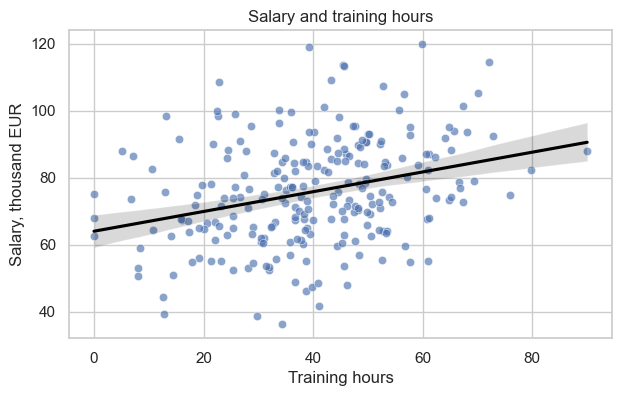

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

- **Outcome:** _salary, in thousand EUR (`salary_k_eur`)._
- **Predictor:** _training hours (`training_hours`)._
- **Expected direction:** _positive. More training should build skills that employers pay for, and the scatter plot and the correlation between training hours and salary (r = 0.30) point the same way._
- **Plausible omitted variable:** _AI tool use (`ai_tool_use`). It is related to both training hours (r = 0.62) and salary (r = 0.40), so a model with only training hours may credit training with part of AI use's effect. Experience is strongly related to salary (r = 0.57) but almost unrelated to training hours (r = -0.07), so it adds noise but is not a confounder. Education behaves the same way (r = 0.02 with training)._

In [6]:
# Correlation matrix for the variables in the model and some additional ones that could be relevant.
df.corr(numeric_only=True).round(2)

,experience_years,education_years,training_hours,remote,ai_tool_use,salary_k_eur,promoted
experience_years,1.00,0.10,-0.07,0.01,0.00,0.57,0.31
education_years,0.10,1.00,0.02,0.06,-0.03,0.30,0.11
training_hours,-0.07,0.02,1.00,-0.04,0.62,0.30,0.33
remote,0.01,0.06,-0.04,1.00,0.14,0.15,0.12
ai_tool_use,0.00,-0.03,0.62,0.14,1.00,0.40,0.41
salary_k_eur,0.57,0.30,0.30,0.15,0.40,1.00,0.37
promoted,0.31,0.11,0.33,0.12,0.41,0.37,1.00


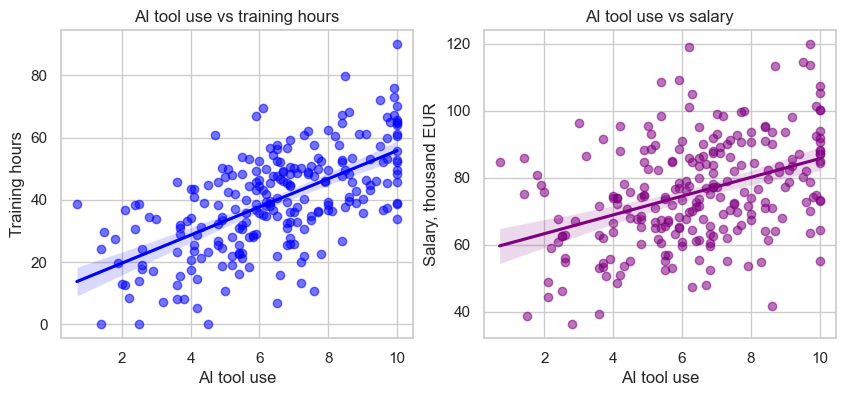

In [7]:
# Does AI tool use go together with both training hours and salary?
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.regplot(data=df, x="ai_tool_use", y="training_hours", scatter_kws={"alpha": 0.55}, color= "blue", ax=axes[0])
sns.regplot(data=df, x="ai_tool_use", y="salary_k_eur", scatter_kws={"alpha": 0.55}, color= "purple", ax=axes[1])
axes[0].set(title="AI tool use vs training hours", xlabel="AI tool use", ylabel="Training hours")
axes[1].set(title="AI tool use vs salary", xlabel="AI tool use", ylabel="Salary, thousand EUR")
plt.show()

_AI tool use is related to both training hours and salary. Experience is related to salary but not to training hours._

In [8]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     26.80
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           4.80e-07
Time:                        05:03:23   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.511     25.

_I used robust (HC3) standard errors, as in the lecture. They stay valid whether or not the spread of errors is even, and they are close to the default ones (0.057 vs 0.060), so the conclusion does not change._

In [9]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
training_sd = df["training_hours"].std()
effect_per_sd = slope * training_sd

print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour (slope): {slope:.3f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour (slope): 0.295 thousand EUR


In [10]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
pred = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(pred[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]]).round(1)

,training_hours,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,10,66.9,63.0,70.8,37.3,96.5
1,40,75.8,73.9,77.7,46.4,105.2
2,80,87.6,82.8,92.4,57.8,117.3


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

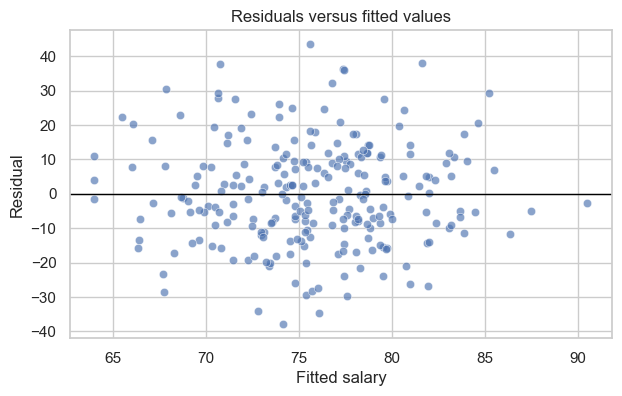

In [11]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

**Result.** _The points are spread evenly around zero, so a straight line is a fair fit. Some workers are still far from the line (up to about 40 thousand EUR). Training hours alone can't explain those differences, which is why R² is low._

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

- **Slope.** _Workers with one more hour of training have, on average, a salary that is 0.295 thousand EUR (about €295) higher._

- **Intercept.** _The fitted average salary at 0 training hours is about 64 thousand EUR. The three zero-hour workers average about 68.5, so this is supported by the data._

- **How much it explains.** _R² = 0.092: training hours explain about 9% of salary variation._

- **Confounder.** _AI tool use is related to both training hours and salary. Workers who use AI more tend to get more training and also earn more. So the 0.295 difference may partly reflect AI use, not training hours alone._

- **Predictions.** _Workers with 40 training hours earn about 75.8 thousand EUR on average. But salaries are spread widely around this average: most workers with 40 hours earn between about 46 and 105 thousand EUR._